# Pollpear AI — comprendre le modèle de feed

Quand quelqu'un ouvre son feed, il faut choisir quels sondages lui montrer, et dans quel ordre.
Pour décider, on ne dispose que de trois informations : qui a voté sur quoi, les hashtags de chaque
sondage, et le nombre de votes reçus.

L'idée générale est simple : donner un score à chaque sondage candidat, puis trier. Le score combine
trois logiques complémentaires :

1. le contenu — « ça ressemble à ce que tu aimes » ;
2. le collaboratif — « les gens qui votent comme toi ont aimé » ;
3. la popularité — « tout le monde en parle ».

Ce notebook déroule chaque étape sur un tout petit exemple, assez petit pour lire tous les calculs
à l'œil nu.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity

from src.training.trainer import (
    _build_hashtag_matrix,
    _build_item_similarity,
    _hashtag_documents,
    build_model,
)

## 1. Un petit exemple

Cinq votants, six sondages. La première table montre les sondages avec leurs hashtags — c'est la
seule description de leur contenu dont on dispose. La deuxième dit qui a voté sur quoi. On ne garde
pas l'option choisie, et on n'en a pas besoin : voter, c'est déjà dire « ce sujet m'intéresse ».

Le dernier sondage (« Qui paye la prochaine tournée ? ») vient d'être créé : personne n'a encore voté
dessus. Gardez-le à l'œil tout au long du notebook.

In [2]:
interactions = pd.DataFrame(
    {
        "user_id": [1, 1, 2, 2, 2, 3, 3, 4, 4, 4, 5, 5],
        "poll_id": [10, 11, 10, 11, 14, 12, 13, 12, 13, 14, 10, 13],
    }
)
poll_hashtags = pd.DataFrame(
    {
        "poll_id": [10, 10, 11, 11, 12, 13, 14, 14, 15, 15],
        "hashtag": ["tech", "school42", "tech", "ai", "valais", "food", "poupou", "valais", "gaming", "tech"],
    }
)
candidates = pd.DataFrame(
    {
        "poll_id": [10, 11, 12, 13, 14, 15],
        "title": [
            "Meilleur framework backend ?",
            "L'IA va-t-elle coder à notre place ?",
            "Est que le Piericsplaining n'est pas que du peer-learning ?",
            "Chinois ou kebab ce soir ?",
            "Faut-il interdire d'allumer la lumière en SSD ?",
            "Qui paye la prochaine tournée ?",
        ],
    }
)
users = {1: "pieric", 2: "hygie", 3: "raphael", 4: "josephine", 5: "benedict"}
labels = {10: "backend", 11: "ia", 12: "piericsplaining", 13: "kebab", 14: "ssd", 15: "tournee"}
polls_view = pd.DataFrame(
    {
        "poll": candidates.poll_id.map(labels),
        "title": candidates.title,
        "hashtags": candidates.poll_id.map(poll_hashtags.groupby("poll_id")["hashtag"].agg(" ".join)),
    }
)
display(polls_view)
interactions.assign(user=interactions.user_id.map(users), poll=interactions.poll_id.map(labels))

,poll,title,hashtags
0,backend,Meilleur framework backend ?,tech school42
1,ia,L'IA va-t-elle coder à notre place ?,tech ai
2,piericsplaining,Est que le Piericsplaining n'est pas que du pe...,valais
3,kebab,Chinois ou kebab ce soir ?,food
4,ssd,Faut-il interdire d'allumer la lumière en SSD ?,poupou valais
5,tournee,Qui paye la prochaine tournée ?,gaming tech


,user_id,poll_id,user,poll
0,1,10,pieric,backend
1,1,11,pieric,ia
2,2,10,hygie,backend
3,2,11,hygie,ia
4,2,14,hygie,ssd
5,3,12,raphael,piericsplaining
6,3,13,raphael,kebab
7,4,12,josephine,piericsplaining
8,4,13,josephine,kebab
9,4,14,josephine,ssd


## 2. Décrire un sondage par ses hashtags

Comment mesurer que deux sondages parlent du même sujet ? On transforme chaque sondage en une liste
de nombres — un vecteur — avec une case par hashtag existant. Si le sondage porte ce hashtag, la case
reçoit un poids ; sinon elle vaut zéro.

Le poids n'est pas un simple 0 ou 1. La technique s'appelle TF-IDF et son intuition tient en une
phrase : un hashtag rare en dit plus qu'un hashtag banal. Savoir qu'un sondage porte school42, présent
sur un seul sondage, est très informatif ; savoir qu'il porte tech, présent un peu partout, l'est
beaucoup moins.

La formule : le poids du hashtag t dans le sondage p vaut

$$w(t, p) = tf(t, p) \times \left( \ln\frac{1 + N}{1 + n_t} + 1 \right)$$

où tf(t, p) compte les occurrences de t dans p (ici un hashtag apparaît au plus une fois par sondage,
donc 0 ou 1), N est le nombre total de sondages, et n_t le nombre de sondages qui portent t. Plus n_t
est petit, plus le logarithme est grand : c'est là que la rareté paye. Les +1 sont juste des
garde-fous : ils évitent une division par zéro et un poids nul.

Chaque vecteur est ensuite divisé par sa longueur, pour que tous les sondages aient la même « taille »
quel que soit leur nombre de hashtags. La longueur d'un vecteur, c'est Pythagore généralisé : la
racine de la somme des carrés de ses cases.

$$\lVert v \rVert = \sqrt{v_1^2 + v_2^2 + \dots} \qquad v_p \leftarrow \frac{v_p}{\lVert v_p \rVert}$$

In [3]:
docs = _hashtag_documents(candidates, poll_hashtags)
vectorizer, tfidf = _build_hashtag_matrix(docs)
vocab = sorted(vectorizer.vocabulary_, key=vectorizer.vocabulary_.get)
pd.DataFrame(tfidf, index=[labels[p] for p in candidates.poll_id], columns=vocab).round(2)

,ai,food,gaming,poupou,school42,tech,valais
backend,0.00,0.0,0.00,0.00,0.82,0.57,0.00
ia,0.82,0.0,0.00,0.00,0.00,0.57,0.00
piericsplaining,0.00,0.0,0.00,0.00,0.00,0.00,1.00
kebab,0.00,1.0,0.00,0.00,0.00,0.00,0.00
ssd,0.00,0.0,0.00,0.77,0.00,0.00,0.63
tournee,0.00,0.0,0.82,0.00,0.00,0.57,0.00


Chaque ligne se lit comme la carte d'identité thématique d'un sondage. Remarquez la dernière ligne :
le sondage tout neuf a déjà sa carte d'identité, alors que personne n'a voté dessus. On peut donc le
recommander sans attendre le moindre vote — dès le prochain entraînement du modèle (on y revient à la
section 7).

Vérifions une case à la main : le 0.82 de school42 sur le sondage backend.

Poids brut de school42, présent sur 1 sondage sur 6 :

$$w = 1 \times \left( \ln\frac{1+6}{1+1} + 1 \right) = \ln(3.5) + 1 \approx 2.25$$

Poids brut de tech, présent sur 3 sondages sur 6 : ln(7/4) + 1 ≈ 1.56. Le vecteur brut de backend
vaut donc (tech : 1.56 ; school42 : 2.25). Sa longueur : √(1.56² + 2.25²) ≈ 2.74. On divise chaque
case par 2.74 : school42 → 2.25 / 2.74 ≈ 0.82 et tech → 1.56 / 2.74 ≈ 0.57 — exactement les valeurs
de la table.

Au passage, le 1.00 de valais sur piericsplaining s'explique : ce sondage n'a qu'un seul hashtag,
donc tout son poids finit dans une seule case, que la division par la longueur ramène forcément à 1.
La normalisation égalise la taille des sondages — elle ne compare pas les raretés entre eux.

## 3. Le profil d'un utilisateur

Les goûts d'un utilisateur, c'est la moyenne des vecteurs des sondages qu'il a votés :

$$profil(u) = \frac{1}{|V_u|} \sum_{p \in V_u} v_p$$

où V_u est l'ensemble des sondages votés par u. Pieric a voté sur le sondage backend et le sondage
ia : son profil pointe donc vers tech, ai et school42.

Pour scorer un candidat, on mesure à quel point son vecteur pointe dans la même direction que le
profil : c'est la similarité cosinus.

$$\cos(a, b) = \frac{a \cdot b}{\lVert a \rVert \times \lVert b \rVert}$$

Le numérateur (le produit scalaire) multiplie les vecteurs case par case puis additionne le tout :
seules les cases où a et b sont non nuls en même temps contribuent — il mesure ce que les deux ont en
commun. Le dénominateur divise par les longueurs et, comme toutes nos valeurs sont positives, le
résultat tombe entre 0 et 1 : proche de 1 pour deux vecteurs qui se ressemblent, 0 pour deux vecteurs
sans rien en commun.

In [4]:
pieric_votes = interactions.loc[interactions.user_id == 1, "poll_id"].tolist()
row = {p: i for i, p in enumerate(candidates.poll_id)}
profile = tfidf[[row[p] for p in pieric_votes]].mean(axis=0, keepdims=True)
content_score = cosine_similarity(profile, tfidf)[0]
not_voted = [p for p in candidates.poll_id if p not in pieric_votes]
pd.Series(
    {labels[p]: content_score[row[p]] for p in not_voted}, name="content score (pieric)"
).round(3).sort_values(ascending=False)

tournee            0.398
piericsplaining    0.000
kebab              0.000
ssd                0.000
Name: content score (pieric), dtype: float64

Le sondage tout neuf sort en tête. Vérifions ce 0.398 à la main : le profil de pieric est la moyenne
des vecteurs de backend (tech : 0.57 ; school42 : 0.82) et de ia (tech : 0.57 ; ai : 0.82), soit
(tech : 0.57 ; school42 : 0.41 ; ai : 0.41). Le vecteur de tournee vaut (tech : 0.57 ; gaming : 0.82).
Une seule case en commun, tech : le produit scalaire vaut 0.57 × 0.57 ≈ 0.32, et en divisant par les
longueurs (0.81 × 1) on obtient 0.398. Les autres candidats n'ont aucune case commune avec le profil,
d'où leurs zéros — cette première méthode ne voit que les hashtags, rien d'autre. D'où la deuxième.

## 4. « Les gens qui ont voté X ont aussi voté Y »

On range les votes dans un grand tableau : une ligne par personne, une colonne par sondage, un 1 quand
la personne a voté. Deux sondages sont alors considérés comme proches si leurs colonnes se ressemblent,
c'est-à-dire si ce sont les mêmes personnes qui ont voté dessus. C'est la même mesure d'angle qu'à
l'étape 3, appliquée cette fois aux colonnes du tableau — et avec des colonnes de 0 et de 1, elle
prend une forme très parlante :

$$sim(X, Y) = \frac{\text{votants communs}}{\sqrt{n_X \times n_Y}}$$

où n_X et n_Y sont les nombres de votants des deux sondages. Aucun hashtag nécessaire : la
ressemblance émerge des comportements.

In [5]:
seen_ids, item_sim = _build_item_similarity(interactions)
sim_labels = [labels[p] for p in seen_ids]
pd.crosstab(interactions.user_id, interactions.poll_id).rename(index=users, columns=labels)

poll_id,backend,ia,piericsplaining,kebab,ssd
user_id,,,,,
pieric,1,1,0,0,0
hygie,1,1,0,0,1
raphael,0,0,1,1,0
josephine,0,0,1,1,1
benedict,1,0,0,1,0


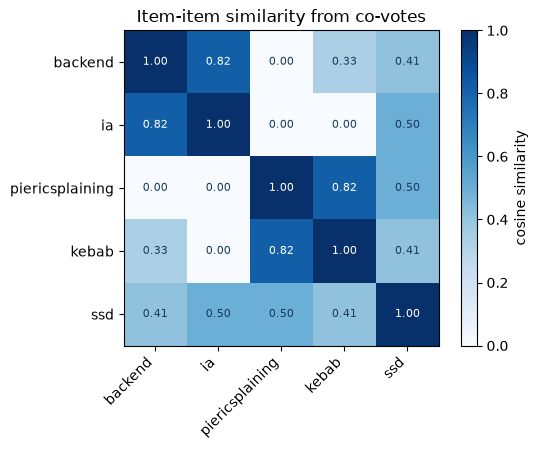

In [6]:
fig, ax = plt.subplots(figsize=(5.8, 4.6))
im = ax.imshow(item_sim, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(sim_labels)), sim_labels, rotation=45, ha="right")
ax.set_yticks(range(len(sim_labels)), sim_labels)
for i in range(len(sim_labels)):
    for j in range(len(sim_labels)):
        ax.text(
            j, i, f"{item_sim[i, j]:.2f}", ha="center", va="center", fontsize=8,
            color="white" if item_sim[i, j] > 0.6 else "#1a3a5c",
        )
fig.colorbar(im, label="cosine similarity")
ax.set_title("Item-item similarity from co-votes")
fig.tight_layout()

Deux familles apparaissent nettement sur la carte : les sondages tech (backend et ia, votés tous
deux par pieric et hygie) et les sondages de raphael et josephine (piericsplaining et kebab).
Benedict fait le pont entre les deux : il est le seul votant commun de backend (3 votants) et kebab
(3 votants), d'où 1 / √(3 × 3) = 0.33 — vérifiable sur la carte.

Le point important : le sondage tout neuf n'apparaît même pas dans cette carte. Zéro vote, zéro
colonne — cette méthode est structurellement aveugle aux nouveautés, alors que la méthode par hashtags
le voyait très bien. Chaque méthode couvre l'angle mort de l'autre : c'est exactement pour ça qu'on
les combine.

## 5. La popularité, le filet de sécurité

Dernier cas à couvrir : quelqu'un qui n'a encore rien voté. Pour lui, les deux méthodes précédentes
donnent zéro partout. Le classement retombe alors naturellement sur « ce qui marche en ce moment »,
tout simplement le nombre de votes reçus :

$$pop(p) = n_p$$

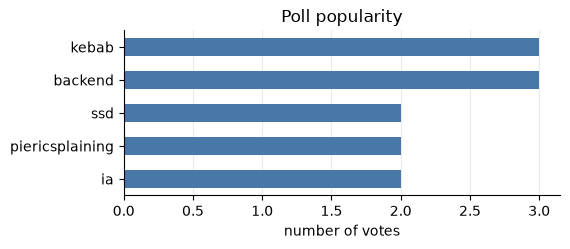

In [7]:
popularity = interactions.groupby("poll_id").size()
pop_sorted = popularity.sort_values()
fig, ax = plt.subplots(figsize=(5.8, 2.6))
ax.barh([labels[p] for p in pop_sorted.index], pop_sorted.values, color="#4878A8", height=0.55)
ax.set_xlabel("number of votes")
ax.set_title("Poll popularity")
ax.spines[["top", "right"]].set_visible(False)
ax.xaxis.grid(True, alpha=0.25)
ax.set_axisbelow(True)
fig.tight_layout()

## 6. Combiner les trois scores

Le score final est une moyenne pondérée des trois :

$$score(p) = \alpha \times content(p) + \beta \times covotes(p) + \gamma \times popularity(p)$$

avec, pour un utilisateur u et un sondage candidat p :

$$content(p) = \cos(profil(u),\, v_p) \qquad
covotes(p) = \max_{q \in V_u} sim(p, q) \qquad
popularity(p) = \frac{n_p}{\max_q n_q}$$

Dans popularity, q parcourt les candidats proposés à u ; dans covotes, un sondage encore jamais voté
vaut 0 par convention (il n'est dans aucune colonne du tableau des votes).

Deux détails comptent. D'abord la normalisation : chaque terme est ramené entre 0 et 1 (c'est le rôle
de la division dans popularity), sans quoi comparer n'aurait pas de sens — un compteur de 49 votes
écraserait toujours une similarité de 0.4. Ensuite le max dans covotes : on garde la meilleure
similarité avec les sondages déjà votés, pas la moyenne. Un seul sondage très proche suffit à dire
« ça devrait lui plaire » ; faire la moyenne noierait ce signal.

Les poids alpha, beta et gamma ne sont pas une vérité mathématique, c'est un choix d'équipe : alpha
fort donne un feed personnalisé, gamma fort un feed tendances. Modifiez les poids dans la cellule
ci-dessous et ré-exécutez-la pour voir le classement bouger.

Le service en production applique exactement cette moyenne pondérée, avec deux termes de plus.
La récence :

$$recency(p) = e^{-\lambda \times age(p)} \qquad \lambda = \frac{\ln 2}{3}$$

où l'âge est en jours : le score de fraîcheur d'un sondage est divisé par deux tous les 3 jours.
C'est elle qui repêche les sondages récents qu'un feed trop « tendances » enterrerait — souvenez-vous
du sondage tout neuf. Et le social : 1 si le sondage a été créé ou voté par un ami, 0 sinon. Les poids
du service — content 0.35, covotes 0.25, recency 0.20, popularity 0.10, social 0.10 — se règlent dans
le fichier recommender du service, et la prochaine étape (l'évaluation) servira à les choisir avec des
chiffres plutôt qu'au jugé.

In [8]:
WEIGHTS = {"content": 0.5, "covotes": 0.3, "popularity": 0.2}

sim_idx = {p: i for i, p in enumerate(seen_ids)}
rows_pieric = [sim_idx[p] for p in pieric_votes]


def norm(s):
    return s / s.max() if s.max() > 0 else s


scores = pd.DataFrame(
    {
        "content": pd.Series({p: content_score[row[p]] for p in not_voted}),
        "covotes": pd.Series(
            {p: item_sim[rows_pieric, sim_idx[p]].max() if p in sim_idx else 0.0 for p in not_voted}
        ),
        "popularity": norm(popularity.reindex(not_voted).fillna(0)),
    }
)
scores["total"] = sum(w * scores[c] for c, w in WEIGHTS.items())
scores.index = [labels[p] for p in scores.index]
scores.round(3).sort_values("total", ascending=False)

,content,covotes,popularity,total
kebab,0.000,0.333,1.000,0.300
ssd,0.000,0.500,0.667,0.283
tournee,0.398,0.000,0.000,0.199
piericsplaining,0.000,0.000,0.667,0.133


Dans le classement final de pieric, chaque logique a son mot à dire : kebab monte grâce à la
popularité et aux co-votes, ssd grâce aux co-votes d'hygie, et le sondage tout neuf uniquement
grâce à ses hashtags.

## 7. Entraîner une fois, servir ensuite

C'est exactement ce que fait le service désormais : au premier appel du feed, il calcule tout —
vecteurs, carte des similarités, compteurs, amitiés, blocages — et garde le résultat en mémoire.
Chaque appel suivant n'est plus que le classement de la section 6, sans toucher à la base. Un appel
d'entraînement dédié permet de rafraîchir le modèle : c'est à ce moment-là qu'un sondage créé
entre-temps entre dans les matrices. Le calcul complet prend quelques millisecondes, on peut donc
rafraîchir très souvent.

Avant le classement, le service retire aussi les sondages que l'utilisateur a déjà votés et ceux des
personnes bloquées. Pas de ML là-dedans, juste du filtrage — mais c'est ce qui rend le feed vivable.

La cellule suivante montre la brique de sauvegarde et rechargement d'un modèle : le notebook s'en
sert pour vérifier qu'un modèle survit intact à un aller-retour sur disque.

In [9]:
import tempfile

from src.models.artifacts import load_latest, save

model = build_model(interactions, poll_hashtags, candidates)
artifact_dir = Path(tempfile.mkdtemp())
path = save(model, artifact_dir)
loaded = load_latest(artifact_dir)
print(path.name)
print("identical poll_ids:", loaded.poll_ids == model.poll_ids)
print("identical tf-idf:", np.array_equal(loaded.hashtag_matrix, model.hashtag_matrix))

feed-model-20260804T012350.349231Z.joblib
identical poll_ids: True
identical tf-idf: True
